In [132]:
import mne
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import ttest_ind
import os
os.makedirs("figures", exist_ok=True)

In [133]:
from mne.datasets import eegbci

files = eegbci.load_data(1, [4])        # subject 1, run 4 (imagined left vs right fist)
raw = mne.io.read_raw_edf(files[0], preload=True)

eegbci.standardize(raw)                 # clean channel names: 'C3..' -> 'C3'
raw.set_montage("standard_1005")        # adds electrode positions

print(raw)
print("Sampling frequency:", raw.info["sfreq"], "Hz")
print("Number of channels:", len(raw.ch_names))

Extracting EDF parameters from C:\Users\Tejasree\mne_data\MNE-eegbci-data\files\eegmmidb\1.0.0\S001\S001R04.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 19999  =      0.000 ...   124.994 secs...
<RawEDF | S001R04.edf, 64 x 20000 (125.0 s), ~9.8 MiB, data loaded>
Sampling frequency: 160.0 Hz
Number of channels: 64


C:\Users\Tejasree\AppData\Local\Temp\ipykernel_31296\1280646285.py:7: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  raw.set_montage("standard_1005")        # adds electrode positions


In [134]:
raw_original= raw.copy()
raw_filtered= raw.copy()

print("Copies created successfully!")
print(type(raw_filtered))

Copies created successfully!
<class 'mne.io.edf.edf.RawEDF'>


In [135]:
raw_filtered.filter(l_freq=1.0, h_freq=40.0, picks="eeg")

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 529 samples (3.306 s)



<RawEDF | S001R04.edf, 64 x 20000 (125.0 s), ~9.8 MiB, data loaded>

In [136]:
print(raw_original.annotations)

<Annotations | 30 segments: T0 (15), T1 (8), T2 (7)>


In [137]:
from collections import Counter
print(Counter(raw_original.annotations.description))

Counter({'T0': 15, 'T1': 8, 'T2': 7})


In [138]:
annotations_table = pd.DataFrame({"Onset_seconds": raw_original.annotations.onset,
                                  "Duration_seconds": raw_original.annotations.duration,
                                  "Label": raw_original.annotations.description})

In [139]:
print(annotations_table.head(15))

    Onset_seconds  Duration_seconds Label
0             0.0               4.2    T0
1             4.2               4.1    T2
2             8.3               4.2    T0
3            12.5               4.1    T1
4            16.6               4.2    T0
5            20.8               4.1    T1
6            24.9               4.2    T0
7            29.1               4.1    T2
8            33.2               4.2    T0
9            37.4               4.1    T2
10           41.5               4.2    T0
11           45.7               4.1    T1
12           49.8               4.2    T0
13           54.0               4.1    T2
14           58.1               4.2    T0


For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


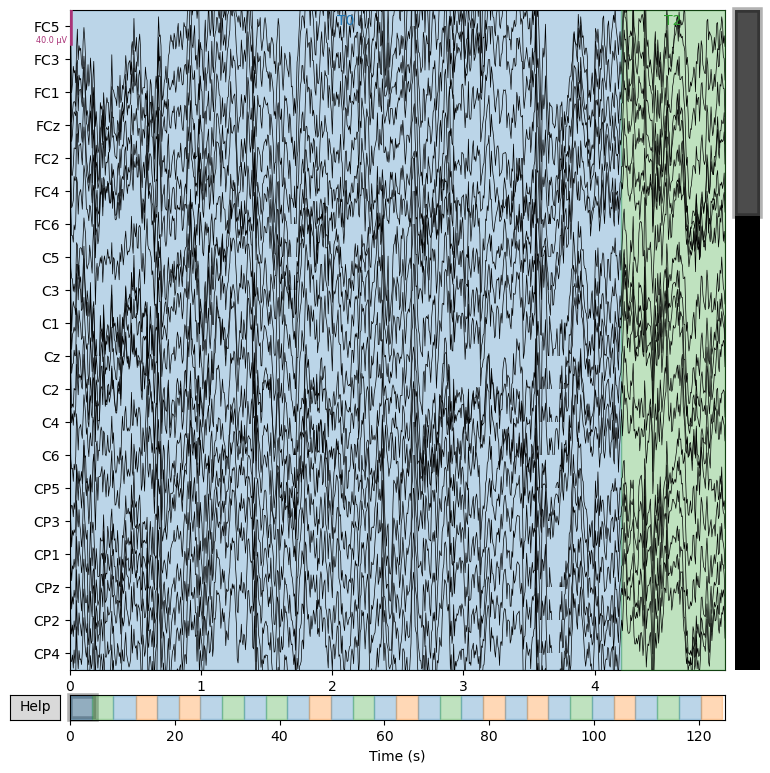

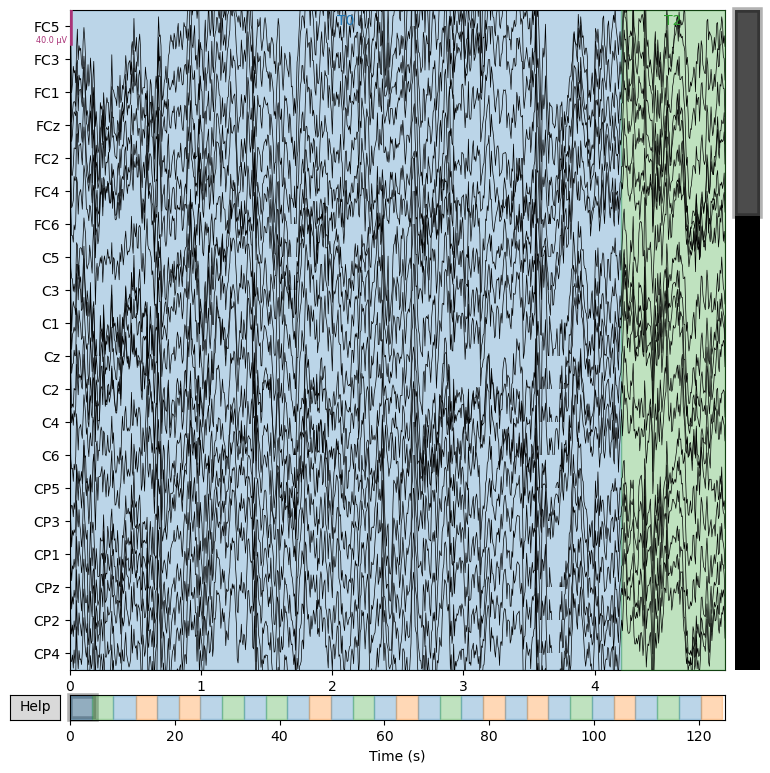

In [140]:
raw_original.plot(duration=5, title="Original EEG")

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


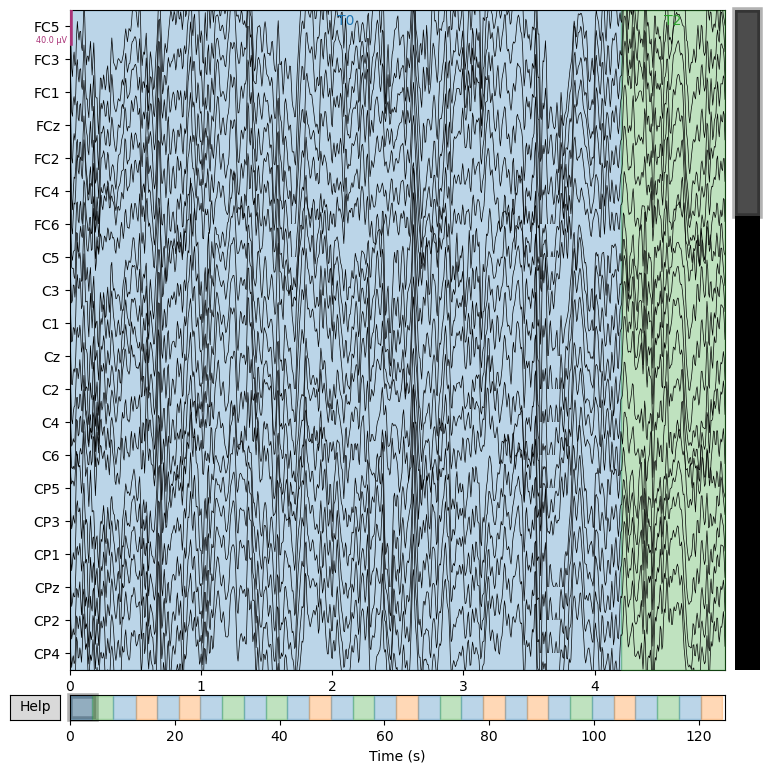

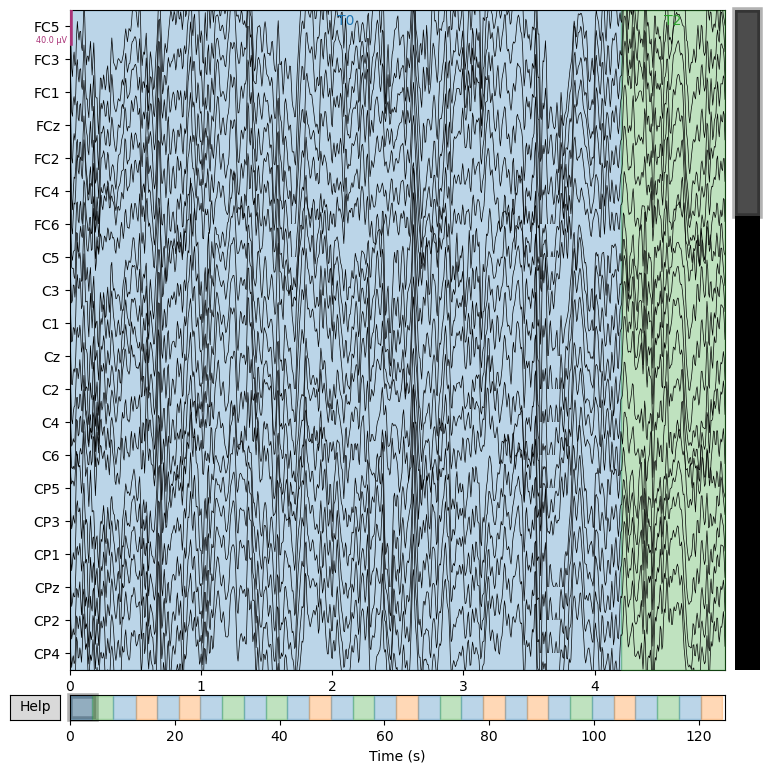

In [141]:
raw_filtered.plot(duration=5, title="Filtered EEG: 1-40 Hz")

In [120]:
fig1 = raw_original.compute_psd(method="welch", fmin=0.5, fmax=45, picks="eeg").plot(show=False)
fig1.savefig("figures/psd_original.png", dpi=200, bbox_inches="tight")

fig2 = raw_filtered.compute_psd(method="welch", fmin=0.5, fmax=45, picks="eeg").plot(show=False)
fig2.savefig("figures/psd_filtered.png", dpi=200, bbox_inches="tight")

Effective window size : 12.800 (s)
Plotting power spectral density (dB=True).
Effective window size : 12.800 (s)
Plotting power spectral density (dB=True).


In [142]:
events, event_id = mne.events_from_annotations(raw_filtered)

print("Event mapping:", event_id)
print("First five events:")
print(events[:5])

Used Annotations descriptions: ['T0', 'T1', 'T2']
Event mapping: {'T0': 1, 'T1': 2, 'T2': 3}
First five events:
[[   0    0    1]
 [ 672    0    3]
 [1328    0    1]
 [2000    0    2]
 [2656    0    1]]


In [143]:
print(event_id)

{'T0': 1, 'T1': 2, 'T2': 3}


In [144]:
print("MNE version:",  mne.__version__)
print("Epoch start:", -0.5)
print("Epoch end:", 4.0)
print("Baseline test:", (-0.5, 0.0))

MNE version: 1.13.2
Epoch start: -0.5
Epoch end: 4.0
Baseline test: (-0.5, 0.0)


In [145]:
selected_events ={"T1": event_id["T1"],
                  "T2": event_id["T2"]}

epochs = mne.Epochs( raw_filtered,
                     events,
                     event_id=selected_events,
                     tmin= -0.5,
                     tmax= 4.0,
                     baseline= (-0.5,0.0),
                     preload=True,
                     reject_by_annotation= True)

print(epochs)
print("Number of T1 epochs:", len(epochs["T1"]))
print("Number of T2 epochs:", len(epochs["T2"]))

Not setting metadata
15 matching events found
Applying baseline correction (mode: mean)
0 projection items activated
Using data from preloaded Raw for 15 events and 721 original time points ...
0 bad epochs dropped
<Epochs | 15 events (all good), -0.5 – 4 s (baseline -0.5 – 0 s), ~5.4 MiB, data loaded,
 'T1': 8
 'T2': 7>
Number of T1 epochs: 8
Number of T2 epochs: 7


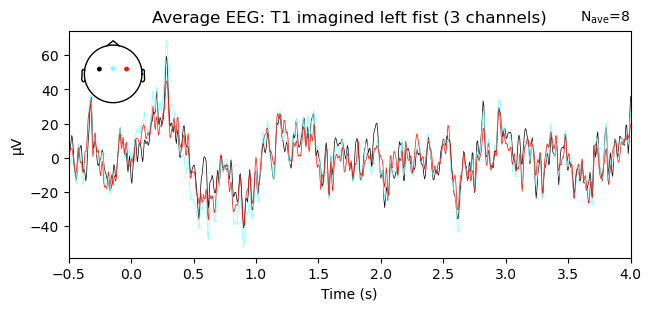

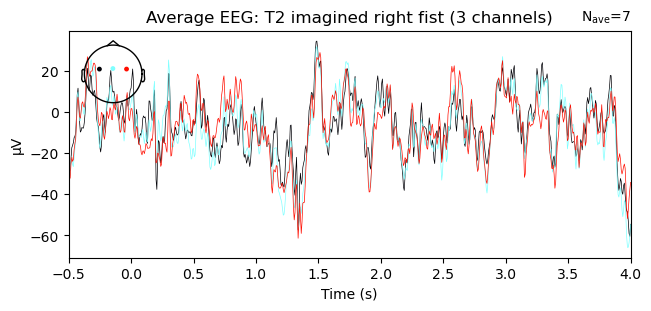

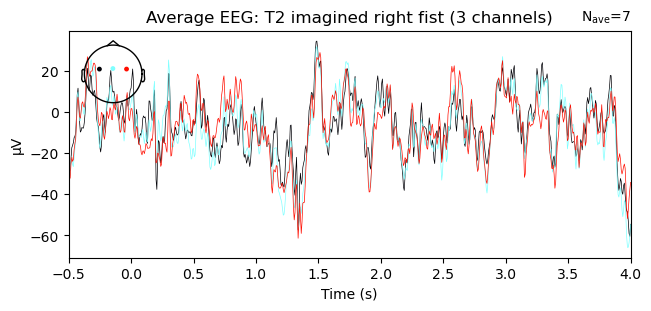

In [146]:
evoked_T1 = epochs["T1"].average()
evoked_T2 = epochs["T2"].average()

evoked_T1.plot( picks=['C3', 'Cz', 'C4'], titles="Average EEG: T1 imagined left fist")

evoked_T2.plot( picks=['C3','Cz', 'C4'], titles= "Average EEG: T2 imagined right fist")

In [147]:
motor_channels = ['C3', 'Cz', 'C4']

spectrum = epochs.compute_psd(
    method="welch",
    picks=motor_channels,
    fmin=8,
    fmax=30,
    n_per_seg=256,
    n_overlap=128
)
psd_data, freqs = spectrum.get_data(return_freqs=True)

print("PSD array shape:", psd_data.shape)
print("Frequency array shape:", freqs.shape)

Effective window size : 4.506 (s)
PSD array shape: (15, 3, 99)
Frequency array shape: (99,)


In [148]:
mu_mask = (freqs >= 8) & (freqs <13)
beta_mask = (freqs >=13) & (freqs <=30)

frequency_step = freqs[1] - freqs[0]

mu_power =psd_data[:,:, mu_mask].sum(axis=-1)*frequency_step
beta_power=psd_data[:,:,beta_mask].sum(axis=-1)*frequency_step

# Convert power from V² to µV²
mu_power = mu_power* 1e12
beta_power = beta_power * 1e12

print("Mu power shape:", mu_power.shape)
print("Beta power shape:", beta_power.shape)

Mu power shape: (15, 3)
Beta power shape: (15, 3)


In [149]:
t1_mask = epochs.events[:,2]==event_id["T1"]
t2_mask = epochs.events[:,2]==event_id["T2"]

mu_T1 =mu_power[t1_mask]
mu_T2 =mu_power[t2_mask]

beta_T1 = beta_power[t1_mask]
beta_T2 = beta_power[t2_mask]

print("T1 mu power shape:", mu_T1.shape)
print("T2 mu power shape:", mu_T2.shape)

T1 mu power shape: (8, 3)
T2 mu power shape: (7, 3)


In [150]:
results=[]

for i, channel in enumerate(motor_channels):
    results.append({
    "channel": channel,
    "T1_mu_mean": mu_T1[:, i].mean(),
    "T2_mu_mean": mu_T2[:,i].mean(), 
    "T1_beta_mean": beta_T1[:,i].mean(),
    "T2_beta_mean": beta_T2[:,i].mean()})

results_df =pd.DataFrame(results)

print(results_df.round(3))

  channel  T1_mu_mean  T2_mu_mean  T1_beta_mean  T2_beta_mean
0      C3     162.422     126.782       193.104       182.741
1      Cz     160.040     144.098       185.543       167.738
2      C4     111.840     136.099       139.797       141.527


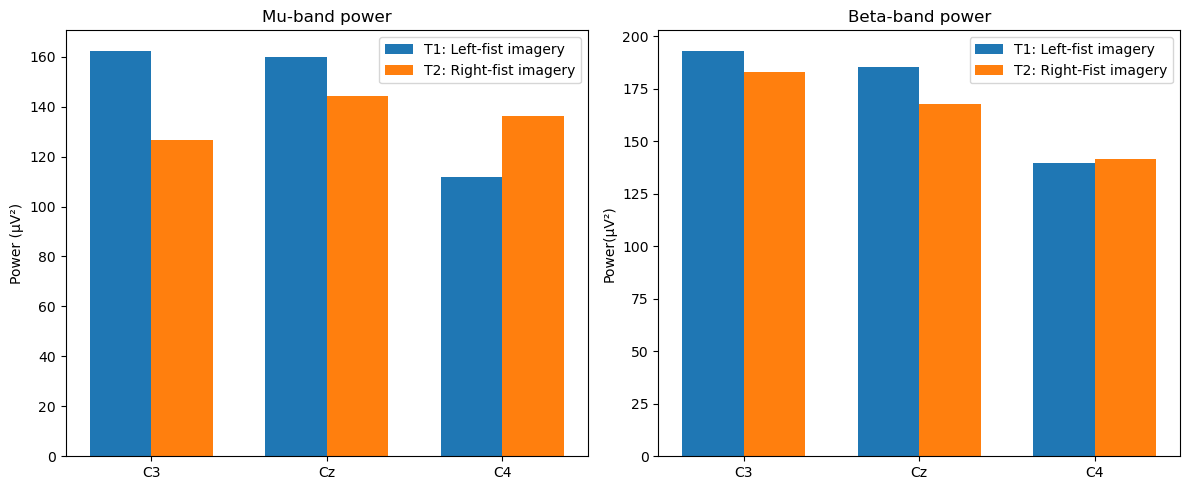

In [151]:
x= np.arange(len(motor_channels))
width = 0.35

fig,axes =plt.subplots(1,2,figsize=(12,5))

axes[0].bar(
    x- width/2, 
    mu_T1.mean(axis=0),
    width,
    label="T1: Left-fist imagery")
axes[0].bar(
    x+ width/2,
    mu_T2.mean(axis=0),
    width,
    label="T2: Right-fist imagery")
axes[0].set_title("Mu-band power")
axes[0].set_xticks(x)
axes[0].set_xticklabels(motor_channels)
axes[0].set_ylabel("Power (µV²)")
axes[0].legend()

axes[1].bar(
    x-width/2,
    beta_T1.mean(axis=0),
    width,
    label="T1: Left-fist imagery")
axes[1].bar(
    x+width/2, 
    beta_T2.mean(axis=0),
    width,
    label="T2: Right-Fist imagery")
axes[1].set_title("Beta-band power")
axes[1].set_xticks(x)
axes[1].set_xticklabels(motor_channels)
axes[1].set_ylabel("Power(µV²)")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/mu_beta_power.png", dpi=200, bbox_inches="tight")
plt.show()

In [131]:
rows = []
for i, channel in enumerate(motor_channels):
    mu_test = ttest_ind(mu_T1[:, i], mu_T2[:, i], equal_var=False)
    beta_test = ttest_ind(beta_T1[:, i], beta_T2[:, i], equal_var=False)
    rows.append({"Channel": channel,
                 "Mu p-value": round(mu_test.pvalue, 4),
                 "Beta p-value": round(beta_test.pvalue, 4)})

results_table = pd.DataFrame(rows)
display(results_table)

,Channel,Mu p-value,Beta p-value
0,C3,0.0707,0.6499
1,Cz,0.2874,0.2950
2,C4,0.2753,0.9050


### Interpretation of Statistical Results

Welch's independent-samples t-tests compared mu-band (8–13 Hz) and beta-band
(13–30 Hz) power between T1 (imagined left fist, n = 8 trials) and T2 (imagined
right fist, n = 7 trials) at the C3, Cz and C4 channels. Band power was
estimated with Welch's method over each full epoch (−0.5 to 4 s).

| Channel | Mu p-value | Beta p-value |
|---|---|---|
| C3 | 0.0707 | 0.6499 |
| Cz | 0.2874 | 0.2950 |
| C4 | 0.2753 | 0.9050 |

**None of the six comparisons reached significance at p < 0.05**, and none
would survive a Bonferroni correction for six tests (p < 0.008). The smallest
p-value was for mu power at C3 (p = 0.071), which is a trend, not a significant
effect.

The mu-band differences were in the direction expected from contralateral
motor-cortex activity. At C3 (left hemisphere), mu power was about 22% lower
during right-fist imagery than during left-fist imagery (127 vs 162 µV²). At C4
(right hemisphere), mu power was about 18% lower during left-fist imagery than
during right-fist imagery (112 vs 136 µV²). Beta power showed no consistent
lateralised pattern: C4 was nearly identical between conditions (140 vs 142 µV²).
Given the sample size, these mu-band differences should be read as exploratory
trends and not as evidence of an effect.

**Limitations.** The analysis used one run from one participant (15 trials), so
statistical power is low. Epochs from the same recording are not fully
independent, which may overstate the evidence in trial-level t-tests. The
comparison is of absolute band power between conditions across the whole epoch,
not event-related desynchronisation (ERD) relative to a pre-cue baseline. No
artefact rejection or multiple-comparison correction was applied in the tests.

**Next steps.** Extend the analysis to more subjects and runs (4, 8 and 12),
quantify ERD as percentage change from baseline using the imagery window only,
test lateralisation across subjects with a paired test, and add a time-frequency
analysis.

